# Partie 1 — Données et faits stylisés

Objectif : télécharger les prix de 5 actions du CAC 40, calculer les pertes du portefeuille,
et montrer que les rendements ne sont pas gaussiens.


In [14]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
from src.data import load_prices, compute_returns, portfolio_losses

tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
prices = load_prices(tickers, "2005-01-01", "2025-12-31", "../data/prices.csv")
returns = compute_returns(prices)
losses = portfolio_losses(returns)

## 1. Statistiques descriptives
On mesure à quel point les rendements s'écartent de la loi normale.

In [16]:
stats = pd.DataFrame({
    "Moyenne":          returns.mean(axis=0),
    "Volatilité ann.":  returns.std(axis=0)*np.sqrt(252),
    "Skewness":         returns.skew(axis=0),
    "Kurtosis":         returns.kurt(axis=0),
    "Pire jour":        returns.min(axis=0),
    "Meilleur jour":    returns.max(axis=0),
})
print(stats)

         Moyenne  Volatilité ann.  Skewness   Kurtosis  Pire jour  \
AIR.PA  0.000468         0.356112 -0.741261  15.182072  -0.305410   
BNP.PA  0.000270         0.366608 -0.042556   9.397518  -0.191166   
MC.PA   0.000527         0.282997  0.160886   4.997641  -0.119305   
SAN.PA  0.000213         0.236094 -0.726002  12.861770  -0.209893   
TTE.PA  0.000284         0.263076 -0.248381  11.548379  -0.181622   

        Meilleur jour  
AIR.PA       0.186175  
BNP.PA       0.188745  
MC.PA        0.121378  
SAN.PA       0.136811  
TTE.PA       0.140407  


**Interprétation**

- **Volatilité** : de 24 % (Sanofi, valeur défensive) à 37 % (BNP, banque exposée aux crises financières).
- **Kurtosis** : entre 5 et 15 pour toutes les actions, alors qu'elle vaut 0 pour une loi normale.
  Les jours extrêmes sont donc beaucoup plus fréquents que ne le prévoit la loi normale.
- **Skewness** : majoritairement négative (sauf LVMH) : les pires chutes sont plus violentes que les meilleures hausses.

**Conséquence pour le projet** : une VaR fondée sur la loi normale risque de sous-estimer
les pertes extrêmes. Il faudra des méthodes qui captent les queues épaisses (historique, EVT).

## 2. Le portefeuille suit-il une loi normale ?

Les 5 actions prises séparément ont toutes des queues épaisses (kurtosis entre 5 et 15).
Mais le projet porte sur le risque du **portefeuille**, pas sur celui de chaque action.

**Hypothèse** : en mélangeant 5 actions, les chocs propres à chaque entreprise devraient
se compenser (effet de diversification). Le rendement du portefeuille pourrait alors
se rapprocher d'une loi normale.

Pour le vérifier, on calcule les mêmes statistiques sur le rendement du portefeuille
équipondéré (rendement = − perte).

In [17]:
port_returns = -losses
print("volatilité ann :", port_returns.std()*np.sqrt(252) )
print("Skewness :", port_returns.skew())
print("Kurtosis :", port_returns.kurt())
print("Pire jour :", port_returns.min())

volatilité ann : 0.22792149437021406
Skewness : -0.2912871362424847
Kurtosis : 7.822616211968597
Pire jour : -0.1310216468659688


**Résultats**

| | Actions | Portefeuille |
|---|---|---|
| Volatilité annuelle | 24 % à 37 % | **22,8 %** |
| Kurtosis | 5 à 15 | **7,8** |
| Skewness | −0,74 à +0,16 | **−0,29** |
| Pire jour | −12 % à −31 % | **−13,1 %** |

**Conclusion : l'hypothèse n'est que partiellement vérifiée.**

- **La diversification réduit le risque au quotidien** : la volatilité du portefeuille (22,8 %)
  est plus faible que celle de la moins volatile des actions (Sanofi, 23,6 %).
  Les chocs propres à une entreprise, comme la chute d'Airbus en 2006, sont dilués.
- **Mais les queues restent épaisses** : la kurtosis (7,8) reste très loin de 0.
  Lors des crises, les 5 actions chutent en même temps : les pertes extrêmes
  ne se compensent pas, elles s'additionnent.
- La skewness reste négative : les fortes baisses sont plus violentes que les fortes hausses.

**Conséquence pour le projet** : même diversifié, le portefeuille ne suit pas une loi normale.
Une VaR gaussienne risque donc de sous-estimer les pertes extrêmes. Il faudra comparer
plusieurs méthodes (historique, KDE, GARCH, EVT) et les valider par backtesting.

## 3. Visualisation des faits stylisés

### 3.1 Rendements du portefeuille dans le temps

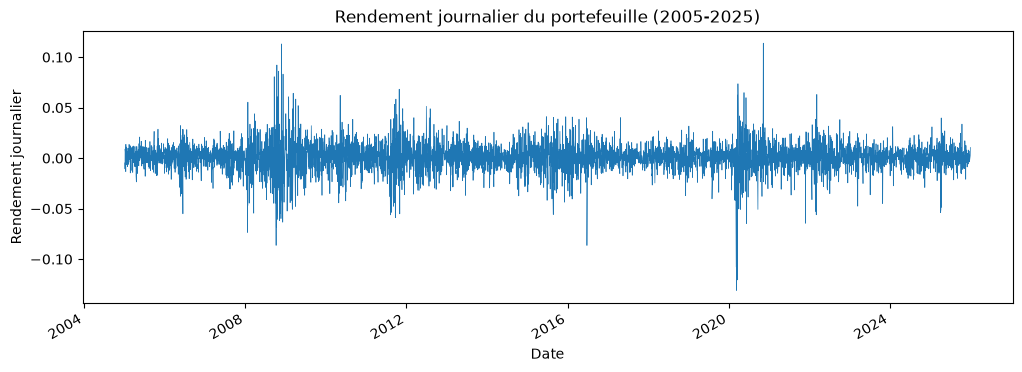

In [18]:
plt.figure(figsize=(12, 4))
port_returns.plot(linewidth=0.5)          
plt.title("Rendement journalier du portefeuille (2005-2025)")                   #
plt.ylabel("Rendement journalier")
plt.savefig("../figures/rendements_portefeuille.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation** : les rendements alternent entre des périodes calmes (2005-2007, 2017-2019, 2023-2025)
et des périodes très agitées : crise financière (2008-2009), crise de la dette européenne (2011),
Brexit (juin 2016), Covid (mars 2020, pire jour : −13 %), annonce du vaccin (novembre 2020, +11 %).

Les journées extrêmes ne sont pas réparties au hasard : elles arrivent **en grappes**.
C'est le **clustering de volatilité**. La volatilité n'est donc pas constante dans le temps,
ce qui motive l'utilisation d'un modèle à volatilité conditionnelle (GARCH, partie 3).

### 3.2 Histograme contre la loi normale

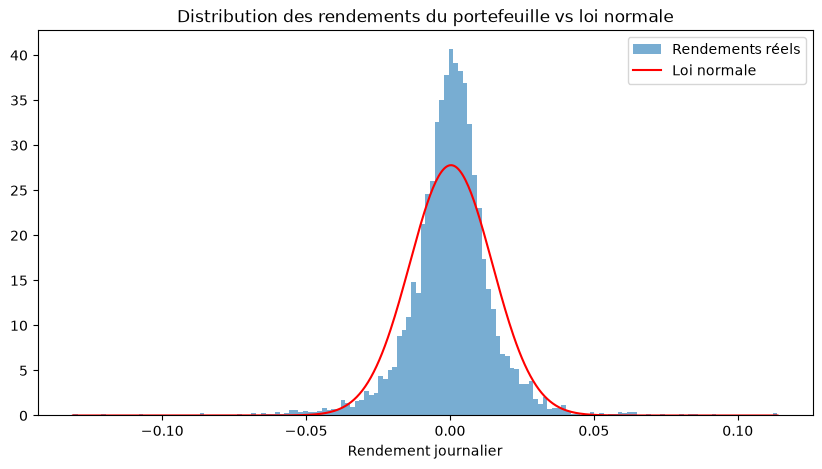

In [19]:
from scipy.stats import norm

plt.figure(figsize=(10, 5))

# 1. L'histogramme du rendement du PF
plt.hist(port_returns, bins=150, density=True, alpha=0.6, label="Rendements réels")

# 2. La loi normale de même moyenne et même écart-type
x = np.linspace(port_returns.min(), port_returns.max(), 500)
mu, sigma = port_returns.mean(), port_returns.std()
plt.plot(x, norm.pdf(x, mu, sigma), color="red", label="Loi normale")

plt.title("Distribution des rendements du portefeuille vs loi normale")
plt.xlabel("Rendement journalier")
plt.legend()
plt.savefig("../figures/histogramme_vs_normale.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation** : la distribution réelle des rendements (en bleu) s'écarte nettement de la loi normale
de même moyenne et de même écart-type (en rouge) :

- **au centre**, le pic est beaucoup plus haut : il y a plus de jours très calmes que prévu ;
- **sur les côtés du pic**, l'histogramme passe sous la courbe : moins de jours « moyens » que prévu ;
- **dans les queues**, il reste des jours extrêmes (jusqu'à −9 %) là où la loi normale prévoit une
  probabilité quasi nulle.
   
Une VaR fondée sur la loi normale sous-estimerait donc la fréquence des grosses pertes.

### 3.3 QQ-plot : comparaison des quantiles avec la loi normale

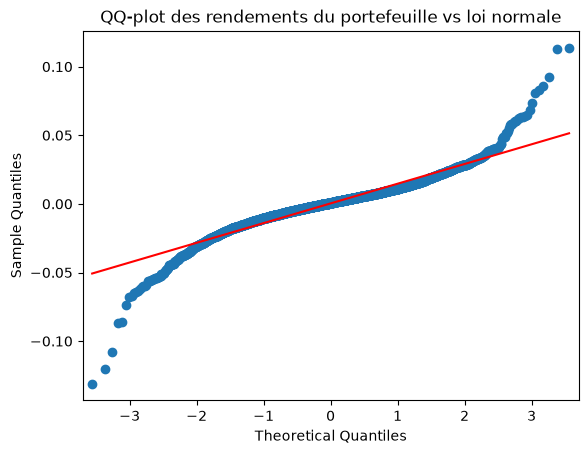

In [20]:
import statsmodels.api as sm

fig = sm.qqplot(port_returns, line="s")
plt.title("QQ-plot des rendements du portefeuille vs loi normale")
plt.savefig("../figures/qqplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture** : chaque point compare un rendement observé (axe vertical) à la valeur que prévoirait
une loi normale au même rang (axe horizontal). Si les rendements étaient
normaux, tous les points seraient sur la droite rouge.

**Observation** :
- au centre (entre −2 et +2 écarts-types), les points suivent la droite : la loi normale décrit
  correctement les jours ordinaires ;
- **dans la queue gauche**, les points plongent sous la droite : le pire jour observé (−13,1 %)
  est plus de deux fois pire que ce que prévoit la loi normale (environ −5 %) ;
- dans la queue droite, les points montent au-dessus de la droite : les fortes hausses sont aussi
  plus extrêmes que prévu.

Cette forme en **S** confirme les **queues épaisses**. La loi normale se trompe précisément dans
la zone qui intéresse la VaR : les pertes extrêmes.

### 3.4 Autocorrélations : les rendements ont-ils une mémoire ?

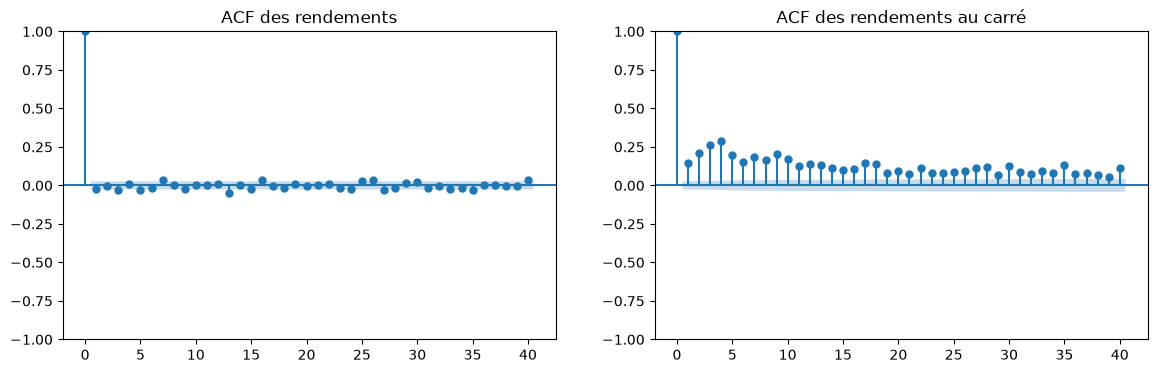

In [21]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(port_returns, lags=40, ax=axes[0])
axes[0].set_title("ACF des rendements")

plot_acf(port_returns**2, lags=40, ax=axes[1])
axes[1].set_title("ACF des rendements au carré")

plt.savefig("../figures/acf.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation** (on ignore la barre au décalage 0, qui vaut toujours 1) :

- **ACF des rendements (à gauche)** : toutes les autocorrélations sont proches de 0 et dans la zone
  de non-significativité. Le rendement passé ne permet pas de prévoir la **direction** du rendement futur.
- **ACF des rendements au carré (à droite)** : toutes les autocorrélations sont positives
  et significatives (entre 0,10 et 0,28), et décroissent très lentement : elles restent nettes
  même après 40 jours.

**Conclusion** : la direction des rendements est imprévisible, mais leur **ampleur** (la volatilité)
est persistante. C'est la confirmation statistique du **clustering de volatilité**, et la justification
d'un modèle à volatilité conditionnelle comme **GARCH** (partie 3).

### 3.5 Volatilité glissante sur 60 jours

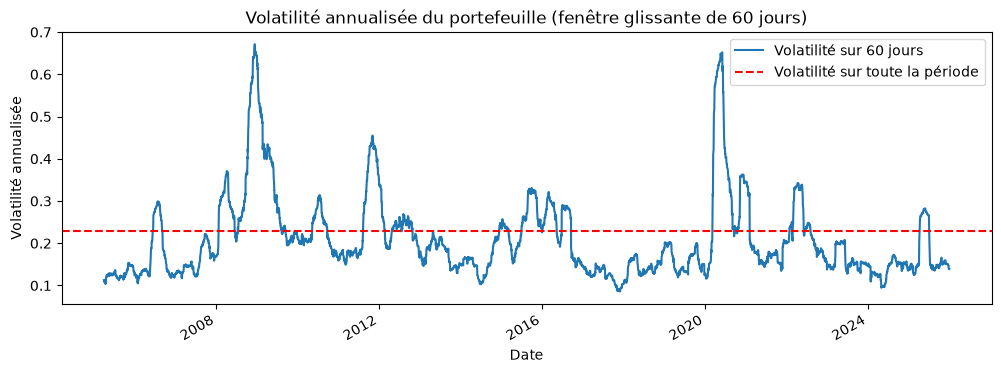

In [22]:
vol_glissante = port_returns.rolling(60).std() * np.sqrt(252)
vol_totale = port_returns.std() * np.sqrt(252)

plt.figure(figsize=(12, 4))
vol_glissante.plot(label="Volatilité sur 60 jours")
plt.axhline(vol_totale, color="red", linestyle="--", label="Volatilité sur toute la période")
plt.title("Volatilité annualisée du portefeuille (fenêtre glissante de 60 jours)")
plt.ylabel("Volatilité annualisée")
plt.legend()
plt.savefig("../figures/volatilite_glissante.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation** : la volatilité varie fortement dans le temps, d'environ 9 % (2017, période calme)
à près de 67 % (fin 2008) et 65 % (mars 2020). La volatilité moyenne sur toute la période (23 %, en rouge)
ne décrit presque jamais la réalité du moment : elle est 3 fois trop faible en crise
et 2 fois trop forte en période calme.

**Conséquence** : une VaR fondée sur une volatilité constante sous-estime le risque pendant les crises,
précisément quand il compte le plus. Il faut un modèle qui adapte la volatilité au jour le jour (GARCH, partie 3).

## 4. Conclusion de la partie 1

L'analyse des rendements du portefeuille équipondéré (TTE, BNP, LVMH, Airbus, Sanofi, 2005-2025)
met en évidence trois faits stylisés :

**1. Des queues épaisses**
- Kurtosis de 7,8 pour le portefeuille (entre 5 et 15 pour les actions), contre 0 pour une loi normale.
- L'histogramme et le QQ-plot montrent que les pertes extrêmes sont bien plus fréquentes et plus violentes
  que prévu : le pire jour (−13,1 %, mars 2020) est plus de deux fois pire que ce que prévoit
  la loi normale.
- La diversification réduit la volatilité (22,8 % contre 24 à 37 % pour les actions seules),
  mais ne fait pas disparaître les queues épaisses : en crise, toutes les actions chutent ensemble.

**2. Une asymétrie négative**
- Skewness de −0,29 : les fortes baisses sont plus violentes que les fortes hausses.

**3. Un clustering de volatilité**
- Les rendements eux-mêmes ne sont pas prévisibles (ACF proche de 0).
- Mais leur ampleur l'est : l'ACF des rendements au carré reste significative pendant plus de 40 jours.
- La volatilité sur 60 jours varie de 9 % (2017) à 67 % (2008) : elle n'est pas constante.

**Conséquences pour la suite du projet**

| Fait observé | Problème pour la VaR | Réponse dans le projet |
|---|---|---|
| Queues épaisses | La VaR gaussienne sous-estime les pertes extrêmes | VaR historique, KDE (partie 2), EVT (partie 4) |
| Volatilité variable | Une VaR à volatilité constante réagit mal aux crises | GARCH (partie 3) |
| Ces deux effets combinés | Il faut savoir quel modèle est vraiment fiable | Backtesting (partie 5) |